In [1]:
library(tidyverse)
library(DESeq2)
library(tximport)
library(rtracklayer)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Loading required package: S4Vectors

Loading required package: stats4

Loading required package: BiocGenerics


Attaching package: ‘BiocGenerics’


The following objects are masked from ‘package:lubridate’:

    intersect, setdiff, union


The following objects are masked from ‘package:dplyr’:

    combine, intersect, setdiff, union


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘package:base’

In [2]:
dir <- "/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/RSEM/GM12878/stimulus_bafinh/"

files <- c(
    "rep1_T1_Veh_r1_anno_rsem.genes.results",
    "rep1_T1_Veh_r2_anno_rsem.genes.results",
    "rep1_T1_Dex_r1_anno_rsem.genes.results",
    "rep1_T1_Dex_r2_anno_rsem.genes.results",
    "rep1_T6_Veh_r1_anno_rsem.genes.results",
    "rep1_T6_Veh_r2_anno_rsem.genes.results",
    "rep1_T6_Dex_r1_anno_rsem.genes.results",
    "rep1_T6_Dex_r2_anno_rsem.genes.results")

In [3]:
#row metadata

gencode <- import("~/manuscripts/BAF_stimulus_CellGenomics/inputs/GENCODE/gencode.v47.annotation.gtf.gz")
gencode <- gencode[which(gencode$type=="gene")]

# create rowdata data frame

rowdata <- as.data.frame(gencode@elementMetadata)

# set rownames to gene id
rownames(rowdata) <- rowdata$gene_id
rowdata$gene_id <- NULL

# create column with "base" gene id without the decimal gene version number
rowdata$gene_id_base <- gsub("\\..*", "", rownames(rowdata))


#  eliminate columns with all NAs
rowdata <- rowdata[,colSums(is.na(rowdata))<nrow(rowdata)]

# add genome coordinates
rowdata$chr <- as.character(gencode@seqnames)
rowdata$start <- as.numeric(gencode@ranges@start)
rowdata$end <- rowdata$start + as.numeric(gencode@ranges@width)

# view summary
nrow(rowdata)
head(rowdata)

[1] 78724

,source,type,gene_type,gene_name,level,tag,hgnc_id,havana_gene,artif_dupl,gene_id_base,chr,start,end
,<fct>,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>
ENSG00000290825.2,HAVANA,gene,lncRNA,DDX11L16,2,overlaps_pseudogene,NA,NA,NA,ENSG00000290825,chr1,11121,24895
ENSG00000223972.6,HAVANA,gene,transcribed_unprocessed_pseudogene,DDX11L1,2,NA,HGNC:37102,OTTHUMG00000000961.2,NA,ENSG00000223972,chr1,12010,13671
ENSG00000310526.1,HAVANA,gene,lncRNA,WASH7P,2,overlaps_pseudogene,HGNC:38034,NA,NA,ENSG00000310526,chr1,14356,30745
ENSG00000227232.6,HAVANA,gene,transcribed_unprocessed_pseudogene,WASH7P,2,overlapping_locus,HGNC:38034,OTTHUMG00000000958.1,NA,ENSG00000227232,chr1,14696,24887
ENSG00000278267.1,ENSEMBL,gene,miRNA,MIR6859-1,3,NA,HGNC:50039,NA,NA,ENSG00000278267,chr1,17369,17437
ENSG00000243485.6,HAVANA,gene,lncRNA,MIR1302-2HG,2,ncRNA_host,HGNC:52482,OTTHUMG00000000959.2,NA,ENSG00000243485,chr1,28589,31110


In [4]:
#read in RSEM data
txi <- tximport(files=paste0(dir,files), type="rsem", txIn=FALSE, txOut=FALSE)


reading in files with read_tsv

1 
2 
3 
4 
5 
6 
7 
8 




In [5]:
#filter and reorder rowdata and txi
int <- intersect(rowdata$gene_id_base, gsub("\\..*", "", rownames(txi$abundance))) 

txi$counts <- txi$counts[match(int,(gsub("\\..*", "", rownames(txi$abundance)))),] 
txi$length <- txi$length[match(int,(gsub("\\..*", "", rownames(txi$abundance)))),]
txi$abundance <- txi$abundance[match(int,(gsub("\\..*", "", rownames(txi$abundance)))),] 
rowdata <- rowdata[match(int, rowdata$gene_id_base), , drop = FALSE] 

In [6]:
keep <- which(apply(txi$abundance, 1, max) >= 1 & apply(txi$length, 1, min) > 0)
txi$counts <- txi$counts[keep,]
txi$abundance <- txi$abundance[keep,]
txi$length <- txi$length[keep,]
rowdata <- rowdata[keep,]

In [7]:
#coldata

coldata <- data.frame("Condition" = c(rep(c("Veh", "Veh", "Dex", "Dex"), 2)),
                     "Time" = c(2,2,2,2,6,6,6,6), "Rep" = rep(c(1,2),4))

In [8]:
txi_2h <- lapply(txi, function(x) {
  if (is.matrix(x) || is.data.frame(x)) {
    x[, 1:4, drop = FALSE]
  } else {
    x  # leave non-matrix entries untouched
  }
})

txi_6h <- lapply(txi, function(x) {
  if (is.matrix(x) || is.data.frame(x)) {
    x[, 5:8, drop = FALSE]
  } else {
    x  # leave non-matrix entries untouched
  }
})

In [9]:
dds_2h <- DESeqDataSetFromTximport(txi=txi_2h, colData=coldata[coldata$Time==2,], design = ~Condition)
des_2h <- DESeq(dds_2h)
res_2h <- results(des_2h, contrast=c("Condition", "Dex", "Veh"))

dds_6h <- DESeqDataSetFromTximport(txi=txi_6h, colData=coldata[coldata$Time==6,], design = ~Condition)
des_6h <- DESeq(dds_6h)
res_6h <- results(des_6h, contrast=c("Condition", "Dex", "Veh"))

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”
using counts and average transcript lengths from tximport

estimating size factors

using 'avgTxLength' from assays(dds), correcting for library size

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”
using counts and average transcript lengths from tximport

estimating size factors

using 'avgTxLength' from assays(dds), correcting for library size

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [12]:
res_6h <- res_6h %>% data.frame() %>% mutate(change=case_when(log2FoldChange < -1 & padj < .05 ~ "down", 
                                                   log2FoldChange > 1 & padj < .05 ~ "up",
                                                   TRUE ~ "not significant")) 

res_2h <- res_2h %>% data.frame() %>% mutate(change=case_when(log2FoldChange < -1 & padj < .05 ~ "down", 
                                                   log2FoldChange > 1 & padj < .05 ~ "up",
                                                   TRUE ~ "not significant")) 

In [16]:
res_6h %>% filter(rowdata$gene_type=="lncRNA") %>% select(change) %>% table()

change
not significant              up 
           1506               4 

Warning message:
“Removed 552 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 552 rows containing missing values or values outside the scale range
(`geom_text()`).”


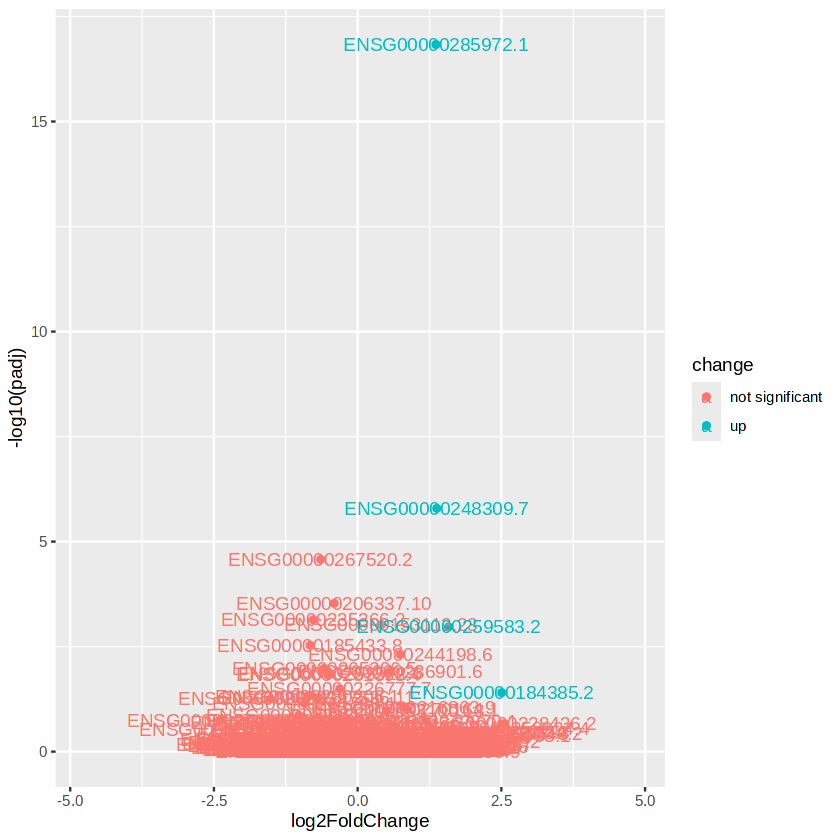

In [21]:
res_6h %>% filter(rowdata$gene_type=="lncRNA") %>% 
    ggplot(aes(x=log2FoldChange,y=-log10(padj), color=change)) + 
    geom_point() + geom_text(aes(label=rownames(res_6h %>% filter(rowdata$gene_type=="lncRNA"))))